# Practicas Splines

## Manuel Cantero Ruiz

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Se ha usado otro método distinto al usado en clase, procedente de un libro recomendado en la guía docedente:

R. L. Burden, J.D.Faires, Análisis Numérico (9ª Ed), Paraninfo,2011.

Este libro tiene un apartado específico para interpolación (Capítulo 3: Interpolation and Polynomial Approximation ) en la que viene detallado el procedimiento usado (páginas 149 y 150)

Lo hemos implementado porque lo hemos visto más comodo para programarlo. Ambos métodos utilizan la condición de que la segunda derivada en los extremos es cero, pero la construcción de la matriz es diferente. En este método, una vez resuelto el sistema, obtenemos las derivadas ( c_i ), y las usamos para encontrar los coeficientes b_i y d_i del polinomio en lugar del proceso visto en clase.


In [2]:
def spline(x, y, t):
    
    # Convertir las listas de entrada en arrays de numpy
    x = np.array(x)
    y = np.array(y)
    t = np.array(t)

    # Número de intervalos
    n = len(x) - 1
    
    # Diferencias entre los puntos x
    h = np.diff(x)
    
    # Pendientes de las líneas secantes entre los puntos y
    alpha = np.diff(y) / h

    # Inicializar el sistema 
    A = np.zeros((n + 1, n + 1))
    b = np.zeros(n + 1)

    # Condicion para que un spline sea natural (segunda derivada igual a 0 en los extremos)
    A[0, 0] = 1
    A[n, n] = 1

    # Rellenar la matriz del sistema y el vector de terminos independientes
    for i in range(1, n):
        A[i, i - 1] = h[i - 1]
        A[i, i] = 2 * (h[i - 1] + h[i])
        A[i, i + 1] = h[i]
        b[i] = 3 * (alpha[i] - alpha[i - 1])

    # Resolver el sistema lineal para obtener los coeficientes c
    c = np.linalg.solve(A, b)

    # Inicializar los coeficientes b y d
    b = np.zeros(n)
    d = np.zeros(n)
    for i in range(n):
        
        # Calcular los coeficientes b usando la primera derivada
        b[i] = alpha[i] - h[i] * (2 * c[i] + c[i + 1]) / 3
        
        # Calcular los coeficientes d usando la segunda derivada
        d[i] = (c[i + 1] - c[i]) / (3 * h[i])

    # Los coeficientes a son simplemente los valores de y en los puntos de soporte
    a = y[:-1]

    # Función para evaluar el spline en un punto dado xi
    def plotspline(xi):
        for i in range(n):
            if x[i] <= xi <= x[i + 1]:
                dx = xi - x[i]
                
                # Evaluar el polinomio spline cúbico en el intervalo correspondiente
                return a[i] + b[i] * dx + c[i] * dx**2 + d[i] * dx**3
        return None

    # Calcular los valores interpolados para cada punto en t
    valores_interpolados = np.array([plotspline(xi) for xi in t])

    return valores_interpolados


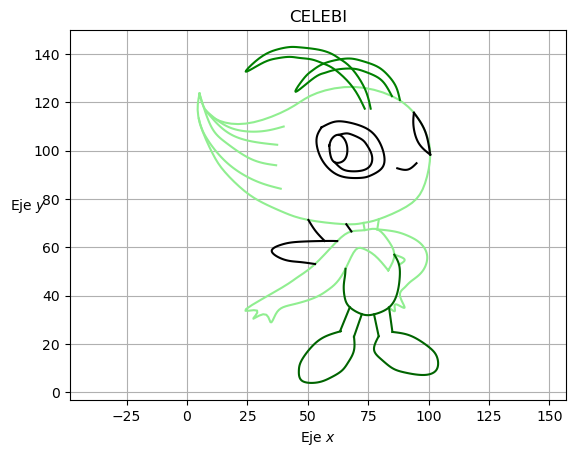

In [3]:
# Cabeza
T_CABEZA = np.linspace(1, 24, 24)
CABEZA_X = np.array([5.17,7.82,14.87,27.35,42.34,52.47,68.48,84.79,93.9,98.5,100.65,98.16,91.61,79.39,72.99,65.92,50.23,40.18,32.34,24.28,15.56,10,4.84,5.17])
CABEZA_Y = np.array([123.62,116.57,111.87,111.72,117.45,123.33,126.41,122.59,115.69,108.11,98.36,85.58,77.35,71.66,70.11,69.56,71.33,74.42,77.95,82.92,91.31,100,113.3,123.62])
PUNTOS_CABEZA = np.linspace(1,24, 100)

eval_cabeza_x = spline(T_CABEZA, CABEZA_X , PUNTOS_CABEZA)
eval_cabeza_y = spline(T_CABEZA, CABEZA_Y , PUNTOS_CABEZA)

# Cuerpo izquierda
T_CUERPO_IZQ = np.linspace(1, 27, 27)
CUERPO_IZQ_X = np.array([83.26,77.96,73.1,69.45,65.59,61.83,58.19,54.32,49.24,44.05,39.74,36.76,34.66,32.23,27.37,28.92,24.28,38.42,45.82,53,62.16,68.02,73.54,78.73,83.04,85.8,83.26])
CUERPO_IZQ_Y = np.array([50.45,56.42,59.4,58.63,51.12,45.37,42.28,39.85,37.86,36.43,35.21,32.45,28.92,32.34,30.46,33.89,34.33,42.83,47.69,53.1,62.6,66.58,67.13,67.46,63.15,56.97,50.45])
PUNTOS_CUERPO_IZQ = np.linspace(1,27, 100)

eval_cuerpo_x = spline(T_CUERPO_IZQ, CUERPO_IZQ_X , PUNTOS_CUERPO_IZQ)
eval_cuerpo_y = spline(T_CUERPO_IZQ, CUERPO_IZQ_Y , PUNTOS_CUERPO_IZQ)

# Brazo derecho
T_BRAZO_DER = np.linspace(1, 13, 13)
BRAZO_DER_X = np.array([78.73,85.9,91.42,96.6,99.39,97.35,92.65,89.92,88.15,90,86.31,86.04,83.59])
BRAZO_DER_Y = np.array([67.46,66.56,64.79,61.66,56.34,50.01,45.92,43.26,39.85,35,36.45,33.72,35.15])
PUNTOS_BRAZO_DER = np.linspace(1,13, 100)

eval_brazo_der_x = spline(T_BRAZO_DER, BRAZO_DER_X , PUNTOS_BRAZO_DER)
eval_brazo_der_y = spline(T_BRAZO_DER, BRAZO_DER_Y , PUNTOS_BRAZO_DER)

# Agujero
T_AGUJERO = np.linspace(1, 3, 3)
AGUJERO_X = np.array([85.8,90,87.74])
AGUJERO_Y = np.array([56.97,55,52.8])
PUNTOS_AGUJERO = np.linspace(1,3, 100)

eval_agujero_x = spline(T_AGUJERO, AGUJERO_X , PUNTOS_AGUJERO)
eval_agujero_y = spline(T_AGUJERO, AGUJERO_Y , PUNTOS_AGUJERO)

# Cuello
T_CUELLO1 = np.linspace(1, 2, 2)
CUELLO_1_X = np.array([73.54,72.99])
CUELLO_1_Y = np.array([67.13,70.11])
PUNTOS_CUELLO1 = np.linspace(1,2, 100)

eval_cuello1_x = spline(T_CUELLO1, CUELLO_1_X , PUNTOS_CUELLO1)
eval_cuello1_y = spline(T_CUELLO1, CUELLO_1_Y , PUNTOS_CUELLO1)


T_CUELLO2 = np.linspace(1, 2, 2)
CUELLO_2_X = np.array([79.39,78.73])
CUELLO_2_Y = np.array([71.66,67.46])
PUNTOS_CUELLO2 = np.linspace(1,2, 100)

eval_cuello2_x = spline(T_CUELLO2, CUELLO_2_X , PUNTOS_CUELLO2)
eval_cuello2_y = spline(T_CUELLO2, CUELLO_2_Y , PUNTOS_CUELLO2)

#Cuerpo Centro
T_CUERPO = np.linspace(1, 12, 12)
CUERPO_CENTRO_X = np.array([85.8,87.74,88.01,86.92,83.59,77.39,72.34,67.37,65.33,64.85,65.33,65.59])
CUERPO_CENTRO_Y = np.array([56.97,52.8,47.42,40.81,35.15,32.29,32.36,35.22,38.97,43.81,47.96,51.12])
PUNTOS_CUERPO_CENTRO = np.linspace(1,12, 100)

eval_cuerpo_centro_x = spline(T_CUERPO, CUERPO_CENTRO_X , PUNTOS_CUERPO_CENTRO)
eval_cuerpo_centro_y = spline(T_CUERPO, CUERPO_CENTRO_Y , PUNTOS_CUERPO_CENTRO)


# Pie izq
T_PIE_IZQ = np.linspace(1, 12, 12)
PIE_IZQ_X = np.array([69.1,69.05,66.69,63.94,59.41,54.01,47.73,46.28,47.44,51.92,57.2,63.65])
PIE_IZQ_Y = np.array([23.04,17.23,12.41,8.87,6.08,4.11,4.69,8.81,13.28,19.21,23.1,25.3])
PUNTOS_PIE_IZQ =  np.linspace(1, 12, 100)

eval_pie_izq_x = spline(T_PIE_IZQ, PIE_IZQ_X , PUNTOS_PIE_IZQ)
eval_pie_izq_y = spline(T_PIE_IZQ, PIE_IZQ_Y , PUNTOS_PIE_IZQ)

# Pierna izquierda
T_PIERNA_IZQ = np.linspace(1, 2, 2)
PIERNA_IZQ_1_X = np.array([67.37,63.33])
PIERNA_IZQ_1_Y = np.array([35.22,25.3])
PIERNA_IZQ_2_X = np.array([72.34,69.1])
PIERNA_IZQ_2_Y = np.array([32.36,23.04])
PUNTOS_PIERNA_IZQ = np.linspace(1, 2, 100)

eval_pierna_izq1_x = spline(T_PIERNA_IZQ, PIERNA_IZQ_1_X , PUNTOS_PIERNA_IZQ)
eval_pierna_izq1_y = spline(T_PIERNA_IZQ, PIERNA_IZQ_1_Y , PUNTOS_PIERNA_IZQ)

eval_pierna_izq2_x = spline(T_PIERNA_IZQ, PIERNA_IZQ_2_X , PUNTOS_PIERNA_IZQ)
eval_pierna_izq2_y = spline(T_PIERNA_IZQ, PIERNA_IZQ_2_Y , PUNTOS_PIERNA_IZQ)


# Pie der
T_PIE_DER = np.linspace(1, 12, 12)
PIE_DER_X = np.array([85,90.3,95.18,100.23,103.42,103.31,98.14,90.36,85,80.49,77.39,79.31])
PIE_DER_Y = np.array([25,24.14,22.11,18.63,14.68,9.45,7.19,8.17,10,13.57,17.64,23.21])
PUNTOS_PIE_DER =  np.linspace(1, 12, 100)

eval_pie_der_x = spline(T_PIE_DER, PIE_DER_X , PUNTOS_PIE_DER)
eval_pie_der_y = spline(T_PIE_DER, PIE_DER_Y , PUNTOS_PIE_DER)

# Pierna derecha
T_PIERNA_DER = np.linspace(1, 2, 2)
PIERNA_DER_1_X = np.array([85,83.59])
PIERNA_DER_1_Y = np.array([25,35.15])
PIERNA_DER_2_X = np.array([79.32,77.39])
PIERNA_DER_2_Y = np.array([23.21,32.29])
PUNTOS_PIERNA_DER = np.linspace(1, 2, 100)

eval_pierna_der1_x = spline(T_PIERNA_DER, PIERNA_DER_1_X , PUNTOS_PIERNA_DER)
eval_pierna_der1_y = spline(T_PIERNA_DER, PIERNA_DER_1_Y , PUNTOS_PIERNA_DER)

eval_pierna_der2_x = spline(T_PIERNA_DER, PIERNA_DER_2_X , PUNTOS_PIERNA_DER)
eval_pierna_der2_y = spline(T_PIERNA_DER, PIERNA_DER_2_Y , PUNTOS_PIERNA_DER)

#Ala abajo

T_ALA_ABAJO =  np.linspace(1, 8, 8)
ALA_ABAJO_X = np.array([62.16,56.97,46.23,39.33,35.06,40,46.48,53])
ALA_ABAJO_Y = np.array([62.6,62.64,62.3,61.19,58.46,55,53.95,53.1])
PUNTOS_ALA_ABAJO =  np.linspace(1, 8, 100)

eval_ala_abajo_x = spline(T_ALA_ABAJO, ALA_ABAJO_X , PUNTOS_ALA_ABAJO)
eval_ala_abajo_y = spline(T_ALA_ABAJO, ALA_ABAJO_Y , PUNTOS_ALA_ABAJO)

# Ala arriba
T_ALA_ARRIBA_1 =np.linspace(1, 3, 3)
ALA_ARRIBA_1_X = np.array([56.97,53.2,50.23])
ALA_ARRIBA_1_Y = np.array([62.64,66.76,71.33])
PUNTOS_ALA_ARRIBA_1 =  np.linspace(1, 3, 100)

eval_ala_arriba_1_x = spline(T_ALA_ARRIBA_1, ALA_ARRIBA_1_X , PUNTOS_ALA_ARRIBA_1)
eval_ala_arriba_1_y = spline(T_ALA_ARRIBA_1, ALA_ARRIBA_1_Y , PUNTOS_ALA_ARRIBA_1)

T_ALA_ARRIBA_2 =np.linspace(1, 2, 2)
ALA_ARRIBA_2_X = np.array([65.92,68.02])
ALA_ARRIBA_2_Y = np.array([69.56,66.58])
PUNTOS_ALA_ARRIBA_2 =  np.linspace(1, 2, 100)

eval_ala_arriba_2_x = spline(T_ALA_ARRIBA_2, ALA_ARRIBA_2_X , PUNTOS_ALA_ARRIBA_2)
eval_ala_arriba_2_y = spline(T_ALA_ARRIBA_2, ALA_ARRIBA_2_Y , PUNTOS_ALA_ARRIBA_2)

# Antena izquierda

T_ANTENA_IZQ = np.linspace(1, 20, 20)
ANTENA_IZQ_X = np.array([76,73.54,68.18,63.47,60,54.48,46.77,42.28,37.03,30.07,24.29,30.93,36.92,42.28,46.67,51.7,56.51,61.33,68.48,73.54])
ANTENA_IZQ_Y = np.array([117.39,125.74,133.98,137.84,140,141.8,142.76,142.87,141.8,138.37,132.7,136.13,138.16,138.82,138.37,137.73,136.02,133.45,126.41,117.39])
PUNTOS_ANTENA_IZQ = np.linspace(1, 20, 100)

eval_antena_izq_x = spline(T_ANTENA_IZQ, ANTENA_IZQ_X , PUNTOS_ANTENA_IZQ)
eval_antena_izq_y = spline(T_ANTENA_IZQ, ANTENA_IZQ_Y , PUNTOS_ANTENA_IZQ)

# Antena derecha

T_ANTENA_DER = np.linspace(1, 19, 19)
ANTENA_DER_X = np.array([88.09,86.38,83.06,78.89,73.32,68.5,63.47,56.51,51.8,48.27,44.95,52.13,56.84,61.33,68.18,73.32,78.35,81.89,84.79])
ANTENA_DER_Y = np.array([121.03,126.7,131.31,134.73,136.87,138.05,137.84,136.02,133.13,129.81,124.35,129.81,132.16,133.45,133.98,132.81,130.67,127.56,122.59])
PUNTOS_ANTENA_DER = np.linspace(1, 19 , 100)

eval_antena_der_x = spline(T_ANTENA_DER, ANTENA_DER_X , PUNTOS_ANTENA_DER)
eval_antena_der_y = spline(T_ANTENA_DER, ANTENA_DER_Y , PUNTOS_ANTENA_DER)

# Ojo derecho

T_OJO_DER =  np.linspace(1, 4, 4)
OJO_DER_X = np.array([100.65,95.81,93.73,93.9])
OJO_DER_Y = np.array([98.36,103.24,110.21,115.69])
PUNTOS_OJO_DER = np.linspace(1, 4 , 100)

eval_ojo_der_x = spline(T_OJO_DER, OJO_DER_X , PUNTOS_OJO_DER)
eval_ojo_der_y = spline(T_OJO_DER, OJO_DER_Y , PUNTOS_OJO_DER)

T_OJO_NEGRO = np.linspace(1, 3, 3)
OJO_NEGRO_X = np.array([100.65,98.5,93.9])
OJO_NEGRO_Y = np.array([98.36,108.11,115.69])
PUNTOS_OJO_NEGRO = np.linspace(1, 3 , 100)

eval_ojo_negro_x = spline(T_OJO_NEGRO, OJO_NEGRO_X , PUNTOS_OJO_NEGRO)
eval_ojo_negro_y = spline(T_OJO_NEGRO, OJO_NEGRO_Y , PUNTOS_OJO_NEGRO)

# Ojo izquierdo
T_OJO_IZQ =  np.linspace(1, 17, 17)
CONTORNO_OJO_X = np.array([55.68,60.54,65.08,70.09,74.68,77.99,80.34,81.68,80.61,76.13,72.34,66.62,61.45,57.18,54.35,53.66,55.68])
CONTORNO_OJO_Y = np.array([109.66,111.85,112.01,110.89,108.97,106.08,102.13,97.28,92.74,89.8,88.79,88.84,90.44,94.23,99.57,105.34,109.66])
PUNTOS_OJO_IZQ = np.linspace(1,17,100)

eval_contorno_ojo_izq_x = spline(T_OJO_IZQ, CONTORNO_OJO_X , PUNTOS_OJO_IZQ)
eval_contorno_ojo_izq_y = spline(T_OJO_IZQ, CONTORNO_OJO_Y , PUNTOS_OJO_IZQ)


T_AZUL_OSCURO = np.linspace(1, 9, 9)
AZUL_OSCURO_X = np.array([58.89,59.31,61.11,64.84,66.35,65.48,62.76,60,58.89])
AZUL_OSCURO_Y = np.array([102.13,98.34,95.21,95.93,99.89,104.16,106.57,105,102.13])
PUNTOS_AZUL_OSCURO = np.linspace(1, 9, 100)

eval_azul_oscuro_x = spline(T_AZUL_OSCURO, AZUL_OSCURO_X , PUNTOS_AZUL_OSCURO)
eval_azul_oscuro_y = spline(T_AZUL_OSCURO, AZUL_OSCURO_Y , PUNTOS_AZUL_OSCURO)

T_INTERIOR = np.linspace(1, 11, 11)
INTERIOR_X = np.array([61.11,63.99,67.64,72.98,76.18,76.39,74.42,72.12,68.17,65.63,62.76])
INTERIOR_Y = np.array([95.21,92.59,91.51,91.94,94.45,98.45,102.35,104.8,106.67,107.14,106.57])
PUNTOS_INTERIOR = np.linspace(1, 11, 100)

eval_interior_x = spline(T_INTERIOR, INTERIOR_X , PUNTOS_INTERIOR)
eval_interior_y = spline(T_INTERIOR, INTERIOR_Y , PUNTOS_INTERIOR)

# Boca
T_BOCA =  np.linspace(1, 3, 3)
BOCA_X = np.array([87,91.37,94.97])
BOCA_Y = np.array([92.73,92.19,94.82])
PUNTOS_BOCA = np.linspace(1, 3, 100)

eval_boca_x = spline(T_BOCA, BOCA_X , PUNTOS_BOCA)
eval_boca_y = spline(T_BOCA, BOCA_Y , PUNTOS_BOCA)

# Lineas de la cabeza

#1
T_LINEA1 =  np.linspace(1, 5, 5)
LINEA_1_X = np.array([38.79,28.03,16.18,7.55,4.84])
LINEA_1_Y = np.array([84.27,87.67,95.33,106.15,113.3])
PUNTOS_LINEA1 =  np.linspace(1, 5, 100)

eval_linea1_x = spline(T_LINEA1, LINEA_1_X , PUNTOS_LINEA1)
eval_linea1_y = spline(T_LINEA1, LINEA_1_Y , PUNTOS_LINEA1)

#2
T_LINEA2 =  np.linspace(1, 5, 5)
LINEA_2_X = np.array([36.88,26.6,16.43,10,5.17])
LINEA_2_Y = np.array([93.97,96.51,103.08,110,123.62])
PUNTOS_LINEA2 =  np.linspace(1, 5, 100)

eval_linea2_x = spline(T_LINEA2, LINEA_2_X , PUNTOS_LINEA2)
eval_linea2_y = spline(T_LINEA2, LINEA_2_Y , PUNTOS_LINEA2)

#3
T_LINEA3 =  np.linspace(1, 3, 3)
LINEA_3_X = np.array([37.31,19.29,7.82])
LINEA_3_Y = np.array([102.45,106.16,116.57])
PUNTOS_LINEA3 =  np.linspace(1, 3, 100)

eval_linea3_x = spline(T_LINEA3, LINEA_3_X , PUNTOS_LINEA3)
eval_linea3_y = spline(T_LINEA3, LINEA_3_Y , PUNTOS_LINEA3)

#4

T_LINEA4 =  np.linspace(1, 4, 4)
LINEA_4_X = np.array([40,30,17.81,7.82])
LINEA_4_Y = np.array([110,107.96,109.55,116.57])
PUNTOS_LINEA4 =  np.linspace(1, 4, 100)

eval_linea4_x = spline(T_LINEA4, LINEA_4_X , PUNTOS_LINEA4)
eval_linea4_y = spline(T_LINEA4, LINEA_4_Y , PUNTOS_LINEA4)


# Graficar los resultados

# Represento los ejes
plt.xlabel('Eje $x$')
plt.ylabel('Eje $y$', rotation=0)


plt.plot(eval_cabeza_x, eval_cabeza_y, color='#90EE90')
plt.plot(eval_cuerpo_x, eval_cuerpo_y, color='#90EE90')
plt.plot(eval_brazo_der_x, eval_brazo_der_y, color='#90EE90')
plt.plot(eval_agujero_x, eval_agujero_y, color='#90EE90')
plt.plot(eval_cuello1_x, eval_cuello1_y, color='#90EE90')
plt.plot(eval_cuello2_x, eval_cuello2_y, color='#90EE90')
plt.plot(eval_cuerpo_centro_x, eval_cuerpo_centro_y, color='#006400')
plt.plot(eval_pie_izq_x, eval_pie_izq_y, color='#006400')
plt.plot(eval_pierna_izq1_x, eval_pierna_izq1_y, color='#006400')
plt.plot(eval_pierna_izq2_x, eval_pierna_izq2_y, color='#006400')
plt.plot(eval_pie_der_x, eval_pie_der_y, color='#006400')
plt.plot(eval_pierna_der1_x, eval_pierna_der1_y, color='#006400')
plt.plot(eval_pierna_der2_x, eval_pierna_der2_y, color='#006400')
plt.plot(eval_ala_abajo_x, eval_ala_abajo_y, color='black')
plt.plot(eval_ala_arriba_1_x, eval_ala_arriba_1_y, color='black')
plt.plot(eval_ala_arriba_2_x, eval_ala_arriba_2_y, color='black')
plt.plot(eval_antena_izq_x, eval_antena_izq_y,  color='green')
plt.plot(eval_antena_der_x, eval_antena_der_y,  color='green')
plt.plot(eval_ojo_der_x, eval_ojo_der_y, color='black')
plt.plot(eval_contorno_ojo_izq_x, eval_contorno_ojo_izq_y, color='black')
plt.plot(eval_boca_x, eval_boca_y, color='black')
plt.plot(eval_linea1_x, eval_linea1_y, color='#90EE90')
plt.plot(eval_linea2_x, eval_linea2_y, color='#90EE90')
plt.plot(eval_linea3_x, eval_linea3_y, color='#90EE90')
plt.plot(eval_linea4_x, eval_linea4_y, color='#90EE90')
plt.plot(eval_azul_oscuro_x, eval_azul_oscuro_y, color='black')
plt.plot(eval_interior_x, eval_interior_y, color='black')
plt.plot(eval_ojo_negro_x, eval_ojo_negro_y, color='black')


plt.title('CELEBI')
plt.plot
plt.grid(True)
plt.axis('equal')
plt.show()

